# Phantom Fairness: auditing fairness against automatically extracted labels

### Part 4 of 4 - Analyses added in response to the reviewers

Run after Parts 2 and 3 (it reads some of their tables). Each section names the comment it answers.

| Section | Analysis | Reviewer comment |
|---|---|---|
| A | Pretraining-exposure audit of every backbone; discrimination by backbone | R4.3 |
| B | Instance dependence with scores never trained on the NLP labels: (i) heads trained on the reference standard by patient-grouped cross-fitting inside the evaluation set; (ii) zero-shot outputs of the CheXpert-only DenseNet | R4.2, R4.3 |
| C | Reference-standard and ontology sensitivity: wider NLP mapping for airspace opacity, an airspace-opacity crosswalk, and the Google test split alone (board-certified panel) | R4.4 |
| D | How large an adjudicated reference set must be to size a regime difference (analytic and simulation) | R4.5 |
| E | Hyperparameter grid search on the validation split, and sensitivity of the conclusions to the chosen value | R1.5 |
| F | Patient-grouped five-fold resampling of the development data (why a fixed split, and how stable the results are) | R1.7 |
| G | Explainability: a model of which positives the NLP labels miss, and class activation maps | R1.8, R2 |
| H | Computational cost: extraction, training and inference times, analysis run times, hardware | R1.4 |
| I | Key numbers for the response letter and the revised manuscript | R1.3 |

---
## 0. Setup

In [1]:
import sys, os, json, time
from pathlib import Path
# phantom_core.py must sit in the same folder as the notebooks.
for _p in (Path.cwd(), Path.cwd() / "notebooks"):
    if (_p / "phantom_core.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import phantom_core as pc

CFG = pc.Config()
CFG.project_dir = r"C:\Users\kruta\Downloads\phantom_fairness"   # the folder that holds table2_headline_phantom_fairness.csv
CFG.ensure_dirs()
CFG.chex_full_pipeline = False
print("Using:", CFG.out)
# Manuscript-run settings are the defaults in phantom_core.Config.
# Set the environment variable PF_QUICK=1 for a fast dry run (small resample counts).
if os.environ.get("PF_QUICK"):
    CFG.n_bootstrap, CFG.n_wcr, CFG.n_inject_mc = 200, 100, 30
    CFG.n_inject_boot, CFG.n_inject_boot_mc, CFG.n_crossfit_splits = 30, 5, 20
VERSIONS = pc.setup_runtime(CFG)
TIMES = pc.Timings(CFG, "part4")
log = pc.log
ARCHIVE = pc.archive_v1_outputs(CFG)
print("Project folder:", CFG.out)
print("Original-submission tables archived at:", ARCHIVE)
print(json.dumps(VERSIONS, indent=2))

Using: C:\Users\kruta\Downloads\phantom_fairness
Project folder: C:\Users\kruta\Downloads\phantom_fairness
Original-submission tables archived at: C:\Users\kruta\Downloads\phantom_fairness\tables\v1_original
{
  "python": "3.11.15",
  "numpy": "2.4.4",
  "pandas": "3.0.3",
  "matplotlib": "3.11.0",
  "platform": "Windows-10-10.0.26300-SP0",
  "sklearn": "1.9.0",
  "scipy": "1.17.1",
  "statsmodels": "0.14.6",
  "torch": "2.12.1+cpu",
  "torchvision": "0.27.1+cpu",
  "torchxrayvision": "1.4.0",
  "open_clip": "3.3.0"
}


In [2]:
with TIMES.track("load_masters_and_cohort"):
    nih_master, padchest_master, ADJ_AUDIT = pc.load_masters(CFG)
    train_df, val_df, test_df, eval_clean = pc.build_cohort(CFG, nih_master)
FRAMES = {"train": train_df, "val": val_df, "evalclean": eval_clean}
NLP_FINDINGS = pc.nlp_findings(CFG)          # Fracture has no NLP label and is handled separately
AXES = pc.SUBGROUP_AXES
CHECK = pc.check_cohort_against_cache(CFG, FRAMES)
if len(CHECK):
    display(CHECK)
    bad = CHECK[~CHECK["match"]]
    if len(bad) and not CFG.allow_reextract:
        raise RuntimeError("The rebuilt cohort does not match the cached embeddings listed above. "
                           "Do not continue: the numbers would not correspond to the original run.")
print(f"train {len(train_df)} | val {len(val_df)} | held-out {len(test_df)} | evaluation {len(eval_clean)} images, "
      f"{eval_clean['patient_id'].nunique()} patients")

22:08:57 [INFO] Loaded master_nih_v2 from cache: 112120 rows


,split,manifest,n,match
0,train,train__clip_vitb32__manifest.json,20000,True
1,train,train__resnet50_imagenet__manifest.json,20000,True
2,train,train__xrv_densenet121__manifest.json,20000,True
3,val,val__clip_vitb32__manifest.json,12930,True
4,val,val__resnet50_imagenet__manifest.json,12930,True
5,val,val__xrv_densenet121__manifest.json,12930,True
6,evalclean,evalclean__clip_vitb32__manifest.json,4376,True
7,evalclean,evalclean__resnet50_imagenet__manifest.json,4376,True
8,evalclean,evalclean__xrv_densenet121__manifest.json,4376,True


train 20000 | val 12930 | held-out 26921 | evaluation 4376 images, 1695 patients


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

EMB, MODELS, EVALS, HEAD_TIMES = {}, {}, {}, {}
for bb in CFG.embedding_backbones:
    if bb == "xrv_densenet121_chex" and not CFG.chex_full_pipeline:
        continue
    try:
        EMB[bb] = pc.embed_frames(CFG, bb, FRAMES)
        if EMB[bb]["train"][0] is None:
            print(f"{bb}: no embeddings; skipped"); EMB.pop(bb); continue
        HEAD_TIMES[bb] = {}
        MODELS[bb] = pc.train_heads(EMB[bb], NLP_FINDINGS, C=CFG.head_C, timings=HEAD_TIMES[bb])
        EVALS[bb] = pc.filter_eval_groups(pc.build_eval_scores(MODELS[bb], bb), AXES, CFG.min_group_n)
    except RuntimeError:
        raise
    except Exception as e:
        log.warning("Backbone %s unavailable: %s", bb, e)
P = CFG.primary_backbone
EVAL = EVALS[P]
print("Backbones:", list(EVALS))

Backbones: ['xrv_densenet121', 'resnet50_imagenet', 'clip_vitb32']


---
## A. Pretraining exposure of each backbone (R4.3)

The primary backbone is TorchXRayVision's `densenet121-res224-all`. Its weights file name and documentation list NIH ChestX-ray14, the Google adjudicated NIH labels and RSNA Pneumonia (whose images are NIH images) among its training data. TorchXRayVision trained on a random patient-level split of each data set but does not distribute the image-level membership, so overlap with the evaluation patients **cannot be ruled out for any evaluation patient**; every evaluation image also carries one of the adjudicated labels that the model may have been trained on. The primary-backbone results are therefore treated as exposed, and each main conclusion is checked on the three unexposed backbones (CheXpert-only DenseNet-121, ImageNet ResNet-50, CLIP ViT-B/32).

In [4]:
try:
    import torchxrayvision as xrv
    MU = xrv.models.model_urls
except Exception:
    MU = {}
rows = []
for bb in CFG.embedding_backbones:
    e = dict(pc.BACKBONE_EXPOSURE[bb]); e = {"backbone": bb, "label": pc.BACKBONE_LABELS[bb], **e}
    w = e["weights"]
    if w in MU:
        e["torchxrayvision_description"] = MU[w].get("description", "")
        e["weights_file"] = MU[w]["weights_url"].split("/")[-1]
    n_pat = eval_clean["patient_id"].nunique()
    e["evaluation_patients_possibly_seen"] = (f"all {n_pat} (cannot be ruled out)" if e["status"] == "exposed"
                                              else ("not documented" if e["nih_images"] == "not documented" else "0"))
    e["analysed_in_this_run"] = bb in EVALS
    rows.append(e)
EXPO = pd.DataFrame(rows); EXPO.to_csv(CFG.tab_dir / "table_backbone_exposure.csv", index=False); display(EXPO)

AUCB = []
for bb, ev in EVALS.items():
    t = pc.subgroup_auroc_table(ev, NLP_FINDINGS, [], n_boot=min(2000, CFG.n_bootstrap), seed=CFG.random_seed, chunk=CFG.boot_chunk)
    t.insert(0, "backbone", bb); AUCB.append(t)
AUCB = pd.concat(AUCB, ignore_index=True)
AUCB.to_csv(CFG.tab_dir / "table_backbone_auroc.csv", index=False)
display(AUCB[["backbone", "finding", "n_images", "n_pos", "auroc", "patient_boot_lo", "patient_boot_hi"]].round(3))

,backbone,label,weights,pretraining_data,nih_images,nih_nlp_labels,adjudicated_labels,status,torchxrayvision_description,weights_file,evaluation_patients_possibly_seen,analysed_in_this_run
0,xrv_densenet121,"DenseNet-121 (TorchXRayVision, all)",densenet121-res224-all,"NIH ChestX-ray14, PadChest, CheXpert, MIMIC-CX...",yes (image-level membership not released; cann...,yes,yes,exposed,This model was trained on the datasets: nih-pc...,nih-pc-chex-mimic_ch-google-openi-kaggle-dense...,all 1695 (cannot be ruled out),True
1,resnet50_imagenet,ResNet-50 (ImageNet),torchvision IMAGENET1K_V2,ImageNet-1k natural images,no,no,no,not exposed,NaN,NaN,0,True
2,clip_vitb32,CLIP ViT-B/32,open_clip ViT-B-32 'openai',"OpenAI web image-text pairs (WIT-400M, not rel...",not documented,no,no,not exposed to labels,NaN,NaN,not documented,True
3,xrv_densenet121_chex,"DenseNet-121 (TorchXRayVision, CheXpert only)",densenet121-res224-chex,CheXpert (Stanford) only,no,no,no,not exposed,,chex-densenet121-d121-tw-lr001-rot45-tr15-sc15...,0,False


,backbone,finding,n_images,n_pos,auroc,patient_boot_lo,patient_boot_hi
0,xrv_densenet121,Airspace opacity,4375,2166,0.826,0.808,0.842
1,xrv_densenet121,Pneumothorax,4375,238,0.717,0.678,0.754
2,xrv_densenet121,Nodule or mass,4375,605,0.697,0.658,0.734
3,resnet50_imagenet,Airspace opacity,4375,2166,0.709,0.689,0.728
4,resnet50_imagenet,Pneumothorax,4375,238,0.705,0.666,0.743
5,resnet50_imagenet,Nodule or mass,4375,605,0.576,0.549,0.604
6,clip_vitb32,Airspace opacity,4375,2166,0.793,0.776,0.809
7,clip_vitb32,Pneumothorax,4375,238,0.744,0.701,0.783
8,clip_vitb32,Nodule or mass,4375,605,0.629,0.594,0.662


---
## B. Instance dependence with scores that were never trained on the NLP labels (R4.2)

Part 3's test uses heads trained on NLP labels, so a lower score for NLP-missed positives partly restates the training target. Two kinds of score break that link:

1. **Reference-trained, cross-fitted heads.** Inside the evaluation set, patients are split into five folds; for each fold, a logistic head is trained on the *reference-standard* labels of the other four folds (C chosen by an inner three-fold patient-grouped search over 0.01, 0.1 and 1) and scores the held-out fold. Repeated with two fold assignments and averaged. Every image is therefore scored by a model that never saw its own label and never saw any NLP label. Because these heads are trained to rank all reference positives above negatives, a lower score for NLP-missed positives here means those images carry less visual evidence of the finding, not that the model learned the NLP labeller's habits.
2. **Zero-shot CheXpert DenseNet.** The native outputs of the CheXpert-only DenseNet-121 (Lung Opacity for airspace opacity, Pneumothorax, Lung Lesion for nodule or mass). This model never saw NIH images, NIH NLP labels or the reference standard; it was trained on CheXpert labels from a different hospital and labeller.

The same four cluster-aware tests as Part 3 are applied; Benjamini-Hochberg adjustment is across all tests in this section.

In [5]:
XFIT_REPEATS, XFIT_K, XFIT_CS = 2, 5, (0.01, 0.1, 1.0)
if os.environ.get("PF_QUICK"): XFIT_REPEATS, XFIT_CS = 1, (0.1,)

def patient_folds(pids, k, seed):
    u = np.unique(np.asarray(pids).astype(str)); r = np.random.default_rng(seed); r.shuffle(u)
    fold_of = {p: i % k for i, p in enumerate(u)}
    return np.array([fold_of[p] for p in np.asarray(pids).astype(str)])

def _fit(X, y, C):
    sc = StandardScaler().fit(X)
    return sc, LogisticRegression(C=C, class_weight="balanced", max_iter=2000).fit(sc.transform(X), y)

def select_C(X, y, pids, seed):
    if len(XFIT_CS) == 1: return XFIT_CS[0]
    f = patient_folds(pids, 3, seed); best = (None, -1)
    for C in XFIT_CS:
        aucs = []
        for k in range(3):
            tr, te = f != k, f == k
            if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2: continue
            sc, mdl = _fit(X[tr], y[tr], C); aucs.append(roc_auc_score(y[te], mdl.predict_proba(sc.transform(X[te]))[:, 1]))
        a = np.mean(aucs) if aucs else -1
        if a > best[1]: best = (C, a)
    return best[0]

def crossfit_reference_scores(X, y, pids, seed):
    oof, chosen = np.zeros(len(y)), []
    for rep in range(XFIT_REPEATS):
        f = patient_folds(pids, XFIT_K, seed + rep); o = np.zeros(len(y))
        for k in range(XFIT_K):
            tr, te = f != k, f == k
            C = select_C(X[tr], y[tr], pids[tr], seed + 10 * rep + k); chosen.append(C)
            sc, mdl = _fit(X[tr], y[tr], C); o[te] = mdl.predict_proba(sc.transform(X[te]))[:, 1]
        oof += o / XFIT_REPEATS
    return oof, chosen

XFIT_INFO = []
for bb, ev in EVALS.items():
    Xev = EMB[bb]["evalclean"][0][ev.index.values]
    pids = ev["patient_id"].astype(str).values
    for f in NLP_FINDINGS:
        t0 = time.perf_counter()
        y = ev["adj_" + f].astype(int).values
        s, chosen = crossfit_reference_scores(Xev, y, pids, CFG.random_seed)
        ev["xfit_" + f] = s
        XFIT_INFO.append({"backbone": bb, "finding": f, "oof_auroc_vs_reference": roc_auc_score(y, s),
                          "C_chosen": json.dumps(pd.Series(chosen).value_counts().to_dict()), "seconds": time.perf_counter() - t0})
    TIMES.record(f"crossfit_reference_heads_{bb}", sum(r["seconds"] for r in XFIT_INFO if r["backbone"] == bb))
XFIT_INFO = pd.DataFrame(XFIT_INFO); XFIT_INFO.to_csv(CFG.tab_dir / "table13a_crossfit_reference_heads.csv", index=False)
display(XFIT_INFO.round(3))

,backbone,finding,oof_auroc_vs_reference,C_chosen,seconds
0,xrv_densenet121,Airspace opacity,0.947,"{""0.01"": 10}",36.417
1,xrv_densenet121,Pneumothorax,0.814,"{""0.01"": 10}",37.900
2,xrv_densenet121,Nodule or mass,0.747,"{""0.01"": 10}",47.135
3,resnet50_imagenet,Airspace opacity,0.866,"{""0.01"": 10}",47.409
4,resnet50_imagenet,Pneumothorax,0.769,"{""0.01"": 10}",42.850
5,resnet50_imagenet,Nodule or mass,0.611,"{""0.01"": 10}",47.959
6,clip_vitb32,Airspace opacity,0.880,"{""0.01"": 10}",23.523
7,clip_vitb32,Pneumothorax,0.769,"{""0.01"": 10}",22.036
8,clip_vitb32,Nodule or mass,0.632,"{""0.01"": 10}",28.967


In [6]:
NAT, NAT_PATHS = pc.get_native_scores(CFG, "evalclean", eval_clean, "xrv_densenet121_chex")
if NAT is not None:
    for f in NLP_FINDINGS:
        EVAL["native_" + f] = NAT[EVAL.index.values, NAT_PATHS.index(pc.NATIVE_MAP[f])]
    print("Zero-shot CheXpert DenseNet AUROC against the reference standard:",
          {f: round(roc_auc_score(EVAL["adj_" + f].astype(int), EVAL["native_" + f]), 3) for f in NLP_FINDINGS})
else:
    print("CheXpert DenseNet native outputs unavailable (needs torch, torchxrayvision and the images).")

IDX = []
with TIMES.track("instance_dependence_nlp_independent"):
    for bb, ev in EVALS.items():
        t = pc.instance_dependence_table(ev, NLP_FINDINGS, CFG, score_prefix="xfit_", label=f"{bb} | reference-trained, cross-fitted")
        t.insert(1, "score_type", "reference-trained head (cross-fitted)"); t.insert(2, "backbone", bb); IDX.append(t)
    if NAT is not None:
        t = pc.instance_dependence_table(EVAL, NLP_FINDINGS, CFG, score_prefix="native_", label="xrv_densenet121_chex | zero-shot native output")
        t.insert(1, "score_type", "zero-shot CheXpert model"); t.insert(2, "backbone", "xrv_densenet121_chex"); IDX.append(t)
IDX = pc.add_bh(pd.concat(IDX, ignore_index=True))
IDX.to_csv(CFG.tab_dir / "table13_instance_dependence_nlp_independent.csv", index=False)
cols = ["score_source", "finding", "rank_biserial", "r_lo_patient", "r_hi_patient", "p_patient_boot_bh", "r_wcr", "p_wcr_bh",
        "gee_adj_or_per_sd_lower", "gee_adj_or_lo", "gee_adj_or_hi", "p_gee_adj_bh"]
display(IDX[[c for c in cols if c in IDX.columns]].round(4))
print(f"Positive r in {int((IDX['rank_biserial'] > 0).sum())} of {len(IDX)}; patient-bootstrap BH p < 0.05 in "
      f"{int((IDX['p_patient_boot_bh'] < 0.05).sum())}; adjusted-GEE BH p < 0.05 in {int((IDX['p_gee_adj_bh'] < 0.05).sum())}")

Zero-shot CheXpert DenseNet AUROC against the reference standard: {'Airspace opacity': 0.876, 'Pneumothorax': 0.698, 'Nodule or mass': 0.542}


,score_source,finding,rank_biserial,r_lo_patient,r_hi_patient,p_patient_boot_bh,r_wcr,p_wcr_bh,gee_adj_or_per_sd_lower,gee_adj_or_lo,gee_adj_or_hi,p_gee_adj_bh
0,"xrv_densenet121 | reference-trained, cross-fitted",Airspace opacity,0.1675,0.1115,0.2257,0.0006,0.1897,0.0000,1.2294,1.1094,1.3623,0.0002
1,"xrv_densenet121 | reference-trained, cross-fitted",Pneumothorax,0.1227,-0.0208,0.2708,0.0502,0.1491,0.0499,1.1550,0.8740,1.5264,0.1696
2,"xrv_densenet121 | reference-trained, cross-fitted",Nodule or mass,0.3583,0.2683,0.4485,0.0006,0.3615,0.0000,1.8806,1.5562,2.2727,0.0000
3,"resnet50_imagenet | reference-trained, cross-f...",Airspace opacity,0.1493,0.0968,0.2004,0.0006,0.1718,0.0000,1.2059,1.0924,1.3312,0.0003
4,"resnet50_imagenet | reference-trained, cross-f...",Pneumothorax,0.1467,0.0047,0.2814,0.0252,0.1040,0.1242,1.2025,0.9395,1.5391,0.0858
5,"resnet50_imagenet | reference-trained, cross-f...",Nodule or mass,0.1508,0.0598,0.2388,0.0021,0.1434,0.0103,1.2818,1.0972,1.4975,0.0017
6,"clip_vitb32 | reference-trained, cross-fitted",Airspace opacity,0.1529,0.0968,0.2074,0.0006,0.1742,0.0000,1.2246,1.1120,1.3484,0.0001
7,"clip_vitb32 | reference-trained, cross-fitted",Pneumothorax,0.1823,0.0335,0.3267,0.0126,0.1170,0.1050,1.2491,0.9449,1.6511,0.0788
8,"clip_vitb32 | reference-trained, cross-fitted",Nodule or mass,0.1766,0.0684,0.2830,0.0010,0.1480,0.0102,1.3517,1.1170,1.6357,0.0017
9,xrv_densenet121_chex | zero-shot native output,Airspace opacity,0.1077,0.0492,0.1665,0.0012,0.1699,0.0000,1.1922,1.0768,1.3200,0.0009


Positive r in 11 of 12; patient-bootstrap BH p < 0.05 in 10; adjusted-GEE BH p < 0.05 in 8


table10b is the original-submission file; run Part 3 first. Plotting NLP-independent scores only.


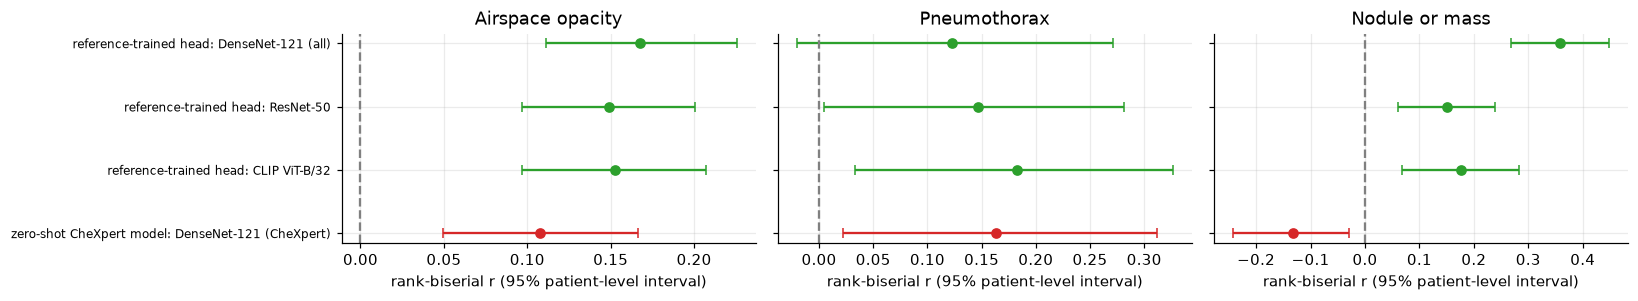

In [8]:
# Forest plot: NLP-trained heads (Part 3) beside NLP-independent scores
parts = []
p3 = CFG.tab_dir / "table10b_instance_dependence_backbones.csv"
if p3.exists():
    a = pd.read_csv(p3)
    if "score_source" in a.columns and "r_lo_patient" in a.columns:
        a["family"] = "NLP-trained head"; a["src"] = a["score_source"].map(pc.BACKBONE_LABELS); parts.append(a)
    else:
        print("table10b is the original-submission file; run Part 3 first. Plotting NLP-independent scores only.")
b = IDX.copy(); b["family"] = np.where(b["score_type"].str.startswith("zero"), "zero-shot CheXpert model", "reference-trained head")
b["src"] = b["backbone"].map(pc.BACKBONE_LABELS); parts.append(b)
F = pd.concat(parts, ignore_index=True)
F.to_csv(CFG.tab_dir / "table13b_instance_dependence_all_sources.csv", index=False)
SHORT = {"xrv_densenet121": "DenseNet-121 (all)", "xrv_densenet121_chex": "DenseNet-121 (CheXpert)",
         "resnet50_imagenet": "ResNet-50", "clip_vitb32": "CLIP ViT-B/32"}
F["bb"] = F["score_source"].str.split(" | ").str[0].map(SHORT).fillna(F["score_source"])
F["row"] = F["family"] + ": " + F["bb"]
order = list(dict.fromkeys(F["row"]))
fig, axs = plt.subplots(1, len(NLP_FINDINGS), figsize=(4.0 * len(NLP_FINDINGS) + 3, 0.36 * len(order) + 1.4), sharey=True)
cmap = {"NLP-trained head": "C0", "reference-trained head": "C2", "zero-shot CheXpert model": "C3"}
ypos = {r: len(order) - 1 - i for i, r in enumerate(order)}
for a_, f in zip(np.atleast_1d(axs), NLP_FINDINGS):
    for _, r in F[F["finding"] == f].iterrows():
        a_.errorbar(r["rank_biserial"], ypos[r["row"]], xerr=[[max(0, r["rank_biserial"] - r["r_lo_patient"])], [max(0, r["r_hi_patient"] - r["rank_biserial"])]],
                    fmt="o", color=cmap[r["family"]], capsize=3)
    a_.axvline(0, color="grey", ls="--"); a_.set_title(f); a_.set_xlabel("rank-biserial r (95% patient-level interval)")
np.atleast_1d(axs)[0].set_yticks(list(ypos.values())); np.atleast_1d(axs)[0].set_yticklabels(list(ypos.keys()), fontsize=8)
plt.savefig(CFG.fig_dir / "fig12_instance_dependence_sources.png", bbox_inches="tight"); plt.show()

---
## C. Reference-standard and ontology sensitivity (R4.4)

**C1. Wider NLP definition of airspace opacity.** The primary mapping is infiltration or consolidation. The wide mapping adds pneumonia, oedema and atelectasis. If much of the prevalence difference reflected a definitional mismatch rather than missed findings, the wide mapping should shrink it; the heads are retrained on the wide labels and every airspace analysis is repeated.

**C2. Crosswalk.** Among reference-standard airspace-opacity positives, the share carrying each NIH label, separately for those the primary mapping caught and missed.

**C3. Google test split only.** The test-split labels were adjudicated by panels of board-certified radiologists only, whereas validation-split panels could include residents. Repeating the key analyses on the test split alone shows whether the reference standard's own quality drives the results.

In [9]:
WIDE = pc.NIH_TO_CANON_WIDE["Airspace opacity"]; FA = "Airspace opacity"
for k, fr in FRAMES.items():
    fr["nlpw_" + FA] = (fr[["nih_" + s for s in WIDE]].sum(axis=1) > 0).astype(int)
rows = []
for name, col in [("primary (infiltration, consolidation)", "nlp_"), ("wide (+ pneumonia, oedema, atelectasis)", "nlpw_")]:
    ya, yn = eval_clean["adj_" + FA].astype(int).values, eval_clean[col + FA].astype(int).values
    st, p_, b_, c_ = pc.mcnemar(yn, ya)
    rows.append({"mapping": name, "nlp_prevalence_eval": yn.mean(), "ref_prevalence_eval": ya.mean(), "agreement": (ya == yn).mean(),
                 "nlp_false_neg": int(((ya == 1) & (yn == 0)).sum()), "nlp_false_pos": int(((ya == 0) & (yn == 1)).sum()),
                 "eps_plus": float((yn[ya == 1] == 0).mean()), "eps_minus": float((yn[ya == 0] == 1).mean()), "mcnemar_p": p_,
                 "nlp_prevalence_full_dataset": nih_master[["nih_" + s for s in (WIDE if col == "nlpw_" else pc.NIH_TO_CANON_TIGHT[FA])]].sum(axis=1).gt(0).mean()})
ONTO = pd.DataFrame(rows); display(ONTO.round(3))

ONTO_ID, ONTO_REG = [], []
for bb in EVALS:
    mw = pc.train_heads(EMB[bb], [FA], C=CFG.head_C, label_prefix="nlpw_")
    ev = EVALS[bb].copy(); ev["scorew_" + FA] = mw["scores_eval"][FA][ev.index.values]
    ev["nlpw_" + FA] = eval_clean.loc[ev.index, "nlpw_" + FA].values
    t = pc.instance_dependence_table(ev, [FA], CFG, score_prefix="scorew_", nlp_prefix="nlpw_", label=bb); ONTO_ID.append(t)
    r = pc.regime_difference_table(ev, [FA], AXES, {FA: mw["thresholds"][FA]}, n_boot=CFG.n_bootstrap, seed=CFG.random_seed,
                                   chunk=CFG.boot_chunk, levels=("patient",), nlp_prefix="nlpw_", score_prefix="scorew_")
    r.insert(0, "backbone", bb); ONTO_REG.append(r)
ONTO_ID = pc.add_bh(pd.concat(ONTO_ID, ignore_index=True)); ONTO_REG = pd.concat(ONTO_REG, ignore_index=True)
ONTO.to_csv(CFG.tab_dir / "table14_ontology_agreement.csv", index=False)
ONTO_ID.to_csv(CFG.tab_dir / "table14_ontology_instance_dependence.csv", index=False)
ONTO_REG.to_csv(CFG.tab_dir / "table14_ontology_regime_difference.csv", index=False)
display(ONTO_ID[["score_source", "rank_biserial", "r_lo_patient", "r_hi_patient", "p_patient_boot_bh", "p_gee_adj_bh"]].round(4))
display(ONTO_REG[["backbone", "axis", "metric", "gap_nlp", "gap_ref", "regime_diff", "diff_lo_patient", "diff_hi_patient"]].round(3))

,mapping,nlp_prevalence_eval,ref_prevalence_eval,agreement,nlp_false_neg,nlp_false_pos,eps_plus,eps_minus,mcnemar_p,nlp_prevalence_full_dataset
0,"primary (infiltration, consolidation)",0.265,0.495,0.645,1280,275,0.591,0.124,0.0,0.208
1,"wide (+ pneumonia, oedema, atelectasis)",0.350,0.495,0.659,1064,428,0.491,0.194,0.0,0.288


,score_source,rank_biserial,r_lo_patient,r_hi_patient,p_patient_boot_bh,p_gee_adj_bh
0,xrv_densenet121,0.1958,0.1444,0.2506,0.0002,0.0000
1,resnet50_imagenet,0.1583,0.1064,0.2088,0.0002,0.0000
2,clip_vitb32,0.1204,0.0673,0.1740,0.0002,0.0003


,backbone,axis,metric,gap_nlp,gap_ref,regime_diff,diff_lo_patient,diff_hi_patient
0,xrv_densenet121,sex,tpr,0.015,0.004,-0.011,-0.051,0.029
1,xrv_densenet121,sex,auroc,0.010,0.005,-0.005,-0.038,0.029
2,xrv_densenet121,age_band,tpr,0.064,0.057,-0.007,-0.075,0.058
3,xrv_densenet121,age_band,auroc,0.034,0.060,0.026,-0.039,0.075
4,xrv_densenet121,view,tpr,0.248,0.193,-0.056,-0.124,0.010
5,xrv_densenet121,view,auroc,0.077,0.120,0.043,-0.013,0.097
6,xrv_densenet121,elderly_women,tpr,0.033,0.007,-0.026,-0.120,0.036
7,xrv_densenet121,elderly_women,auroc,0.017,0.018,0.001,-0.081,0.045
8,resnet50_imagenet,sex,tpr,0.044,0.041,-0.003,-0.048,0.039
9,resnet50_imagenet,sex,auroc,0.031,0.052,0.021,-0.021,0.060


In [10]:
# C2. Crosswalk of NIH labels among reference-standard airspace-opacity positives
pos = eval_clean[eval_clean["adj_" + FA] == 1]
rows = []
for lab in pc.NIH14 + ["No_Finding"]:
    c = "nih_" + lab
    rows.append({"NIH label": lab, "all_ref_positives_pct": 100 * pos[c].mean(),
                 "caught_by_primary_mapping_pct": 100 * pos.loc[pos["nlp_" + FA] == 1, c].mean(),
                 "missed_by_primary_mapping_pct": 100 * pos.loc[pos["nlp_" + FA] == 0, c].mean()})
XWALK = pd.DataFrame(rows).sort_values("missed_by_primary_mapping_pct", ascending=False)
XWALK.to_csv(CFG.tab_dir / "table14b_airspace_crosswalk.csv", index=False); display(XWALK.round(1))

,NIH label,all_ref_positives_pct,caught_by_primary_mapping_pct,missed_by_primary_mapping_pct
14,No_Finding,27.7,0.0,46.8
2,Effusion,25.2,28.6,22.8
0,Atelectasis,16.2,22.7,11.7
7,Pneumothorax,7.6,5.0,9.5
4,Mass,8.6,7.7,9.3
5,Nodule,7.2,7.3,7.0
9,Edema,6.0,8.0,4.5
10,Emphysema,3.1,2.4,3.6
12,Pleural_Thickening,3.9,5.1,3.1
1,Cardiomegaly,3.2,4.2,2.5


In [11]:
# C3. Google test split only (board-certified adjudication panels)
SPLIT_ROWS, SPLIT_ID = [], []
for sid in ("test", "val"):
    for bb, ev in EVALS.items():
        evs = pc.filter_eval_groups(ev[ev["gmeta_set_id"] == sid].copy(), AXES, CFG.min_group_n)
        if len(evs) < 100: continue
        t = pc.instance_dependence_table(evs, NLP_FINDINGS, CFG, label=f"{bb} | split={sid}"); t.insert(1, "split", sid); SPLIT_ID.append(t)
        if bb == P:
            for f in NLP_FINDINGS:
                ya, yn = evs["adj_" + f].astype(int).values, evs["nlp_" + f].astype(int).values
                SPLIT_ROWS.append({"split": sid, "finding": f, "images": len(evs), "patients": evs["patient_id"].nunique(),
                                   "ref_prevalence": ya.mean(), "nlp_prevalence": yn.mean(), "eps_plus": float((yn[ya == 1] == 0).mean()),
                                   "eps_minus": float((yn[ya == 0] == 1).mean())})
            rg = pc.regime_difference_table(evs, NLP_FINDINGS, AXES, MODELS[P]["thresholds"], n_boot=CFG.n_bootstrap, seed=CFG.random_seed,
                                            chunk=CFG.boot_chunk, levels=("patient",))
            rg.insert(0, "split", sid); rg.to_csv(CFG.tab_dir / f"table15_regime_difference_split_{sid}.csv", index=False)
            print(f"split={sid}: reference gap larger in {int((rg['regime_diff'] > 0).sum())} of {len(rg)}; median {rg['regime_diff'].median():.3f}")
SPLIT_NOISE = pd.DataFrame(SPLIT_ROWS); SPLIT_ID = pc.add_bh(pd.concat(SPLIT_ID, ignore_index=True)) if SPLIT_ID else pd.DataFrame()
SPLIT_NOISE.to_csv(CFG.tab_dir / "table15_reference_split_noise.csv", index=False)
SPLIT_ID.to_csv(CFG.tab_dir / "table15_reference_split_instance_dependence.csv", index=False)
display(SPLIT_NOISE.round(3))
if len(SPLIT_ID): display(SPLIT_ID[["score_source", "finding", "n_missed", "n_caught", "rank_biserial", "r_lo_patient", "r_hi_patient", "p_patient_boot_bh"]].round(4))

split=test: reference gap larger in 15 of 24; median 0.019
split=val: reference gap larger in 13 of 24; median 0.009


,split,finding,images,patients,ref_prevalence,nlp_prevalence,eps_plus,eps_minus
0,test,Airspace opacity,1962,860,0.578,0.297,0.582,0.132
1,test,Pneumothorax,1962,860,0.099,0.102,0.503,0.058
2,test,Nodule or mass,1962,860,0.150,0.121,0.546,0.062
3,val,Airspace opacity,2413,834,0.427,0.240,0.600,0.120
4,val,Pneumothorax,2413,834,0.018,0.016,0.721,0.011
5,val,Nodule or mass,2413,834,0.128,0.090,0.606,0.046


,score_source,finding,n_missed,n_caught,rank_biserial,r_lo_patient,r_hi_patient,p_patient_boot_bh
0,xrv_densenet121 | split=test,Airspace opacity,661,474,0.2112,0.1475,0.2744,0.0006
1,xrv_densenet121 | split=test,Pneumothorax,98,97,0.1269,-0.0235,0.2799,0.0585
2,xrv_densenet121 | split=test,Nodule or mass,161,134,0.1933,0.0663,0.3201,0.0045
3,resnet50_imagenet | split=test,Airspace opacity,661,474,0.1388,0.0674,0.2102,0.0006
4,resnet50_imagenet | split=test,Pneumothorax,98,97,0.1163,-0.0720,0.2917,0.1102
5,resnet50_imagenet | split=test,Nodule or mass,161,134,0.1113,-0.0112,0.2279,0.0576
6,clip_vitb32 | split=test,Airspace opacity,661,474,0.1884,0.1205,0.2558,0.0006
7,clip_vitb32 | split=test,Pneumothorax,98,97,0.0669,-0.1056,0.2436,0.2328
8,clip_vitb32 | split=test,Nodule or mass,161,134,0.1785,0.0306,0.3137,0.0173
9,xrv_densenet121 | split=val,Airspace opacity,619,412,0.1900,0.1047,0.2807,0.0006


---
## D. How large must an adjudicated reference set be? (R4.5)

The submission said a "small" adjudicated set is needed to detect hidden disparities. This section replaces that phrase with a number. For each of the 24 comparisons, the patient-level bootstrap standard error of the regime difference (Part 2) is scaled as 1/√(patients) to give the number of adjudicated patients needed for 80% power at two-sided α = 0.05 (and at a Bonferroni α of 0.05/24), for true regime differences of 0.05, 0.10 and 0.15. This is a planning calculation for future audits, not a post-hoc power analysis of this study. A simulation check for the two largest observed differences resamples studies of 1 to 8 times the current number of patients from the evaluation set, analyses each with the patient-level bootstrap, and counts how often the interval excludes zero (power conditional on the observed difference being the true one). Where the simulated power is lower than the analytic power, quote the simulated value: the gap statistic is biased under resampling, so the analytic figure is optimistic.

In [12]:
T2 = pd.read_csv(CFG.tab_dir / "table2_headline_phantom_fairness.csv")
za, zb, zbf = norm.ppf(0.975), norm.ppf(0.80), norm.ppf(1 - 0.05 / (2 * len(T2)))
rows = []
for _, r in T2.iterrows():
    se, n = r["diff_se_patient"], r["n_patients"]
    rec = {"finding": r["finding"], "axis": r["axis"], "metric": r["metric"], "observed_diff": r["regime_diff"], "se_patient": se,
           "patients_now": n, "images_now": r["n_images"]}
    for d in (0.05, 0.10, 0.15):
        rec[f"patients_needed_delta_{d:.2f}"] = int(np.ceil(n * ((za + zb) * se / d) ** 2))
        rec[f"patients_needed_delta_{d:.2f}_bonferroni"] = int(np.ceil(n * ((zbf + zb) * se / d) ** 2))
    rec["patients_needed_observed_diff"] = int(np.ceil(n * ((za + zb) * se / abs(r["regime_diff"])) ** 2)) if abs(r["regime_diff"]) > 1e-6 else np.nan
    rows.append(rec)
SIZE = pd.DataFrame(rows); SIZE.to_csv(CFG.tab_dir / "table16_reference_set_size.csv", index=False)
display(SIZE.round(3))
print("Median adjudicated patients needed for 80% power, two-sided alpha 0.05:",
      {d: int(SIZE[f"patients_needed_delta_{d:.2f}"].median()) for d in (0.05, 0.10, 0.15)},
      "| current:", int(SIZE["patients_now"].iloc[0]))

,finding,axis,metric,observed_diff,se_patient,patients_now,images_now,patients_needed_delta_0.05,patients_needed_delta_0.05_bonferroni,patients_needed_delta_0.10,patients_needed_delta_0.10_bonferroni,patients_needed_delta_0.15,patients_needed_delta_0.15_bonferroni,patients_needed_observed_diff
0,Airspace opacity,sex,tpr,-0.010,0.022,1694,4375,2521,4935,631,1234,281,549,57286
1,Airspace opacity,sex,auroc,0.029,0.021,1694,4375,2274,4451,569,1113,253,495,6897
2,Airspace opacity,age_band,tpr,0.040,0.041,1694,4375,8816,17256,2204,4314,980,1918,13443
3,Airspace opacity,age_band,auroc,0.014,0.029,1694,4375,4504,8816,1126,2204,501,980,57491
4,Airspace opacity,view,tpr,-0.001,0.040,1694,4375,8606,16847,2152,4212,957,1872,23744467
5,Airspace opacity,view,auroc,0.067,0.031,1694,4375,5114,10011,1279,2503,569,1113,2889
6,Airspace opacity,elderly_women,tpr,-0.039,0.048,1694,4375,12028,23545,3007,5887,1337,2617,19682
7,Airspace opacity,elderly_women,auroc,-0.061,0.034,1694,4375,6138,12014,1535,3004,682,1335,4170
8,Pneumothorax,sex,tpr,0.002,0.062,1694,4375,20279,39696,5070,9924,2254,4411,8352737
9,Pneumothorax,sex,auroc,0.030,0.037,1694,4375,7340,14368,1835,3592,816,1597,20946


Median adjudicated patients needed for 80% power, two-sided alpha 0.05: {0.05: 9750, 0.1: 2437, 0.15: 1084} | current: 1694


,finding,axis,metric,multiplier,patients,images_approx,empirical_power,studies,analytic_power
0,Pneumothorax,elderly_women,tpr,1,1694,4375,0.075,200,0.323
1,Pneumothorax,elderly_women,tpr,2,3388,8750,0.270,200,0.564
2,Pneumothorax,elderly_women,tpr,4,6776,17500,0.690,200,0.851
3,Pneumothorax,elderly_women,tpr,8,13552,35000,0.930,200,0.989
4,Nodule or mass,elderly_women,auroc,1,1694,4375,0.325,200,0.544
5,Nodule or mass,elderly_women,auroc,2,3388,8750,0.750,200,0.833
6,Nodule or mass,elderly_women,auroc,4,6776,17500,0.980,200,0.985
7,Nodule or mass,elderly_women,auroc,8,13552,35000,1.000,200,1.000


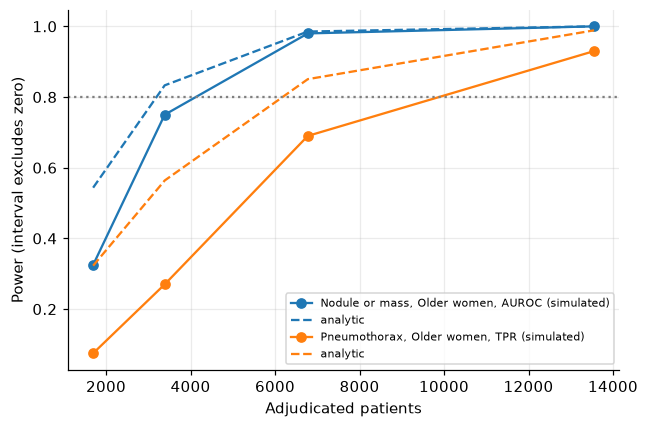

In [13]:
def empirical_power(ev, f, ax, metric, thr, mults=(1, 2, 4, 8), n_studies=200, n_boot=200, seed=CFG.random_seed):
    sub = ev[ev["adj_" + f].notna()].reset_index(drop=True)
    eng = pc.GapEngine(sub[ax].values, sub["score_" + f].values, thr, {"nlp": sub["nlp_" + f].values, "adj": sub["adj_" + f].values})
    codes, nc = pc.encode_clusters(sub["patient_id"].values); rng = np.random.default_rng(seed); out = []
    for mlt in mults:
        N = mlt * nc; hits = valid = 0
        for _ in range(n_studies):
            study = rng.integers(0, nc, N)
            draws = study[rng.integers(0, N, size=(n_boot, N))]
            flat = (np.arange(n_boot)[:, None] * nc + draws).ravel()
            W = np.bincount(flat, minlength=n_boot * nc).reshape(n_boot, nc).astype(float)[:, codes]
            d = eng.gaps(W, "adj", metric) - eng.gaps(W, "nlp", metric); d = d[~np.isnan(d)]
            if len(d) < 20: continue
            lo, hi = np.percentile(d, [2.5, 97.5]); valid += 1; hits += int(lo > 0 or hi < 0)
        out.append({"finding": f, "axis": ax, "metric": metric, "multiplier": mlt, "patients": N, "images_approx": mlt * len(sub),
                    "empirical_power": hits / max(1, valid), "studies": valid})
    return out
top = T2.reindex(T2["regime_diff"].sort_values(ascending=False).index).head(2)
n_st = 40 if os.environ.get("PF_QUICK") else 200
with TIMES.track("power_simulation"):
    POW = pd.DataFrame(sum([empirical_power(EVAL, r["finding"], r["axis"], r["metric"], MODELS[P]["thresholds"][r["finding"]], n_studies=n_st)
                            for _, r in top.iterrows()], []))
for i, r in POW.iterrows():
    s = SIZE[(SIZE["finding"] == r["finding"]) & (SIZE["axis"] == r["axis"]) & (SIZE["metric"] == r["metric"])].iloc[0]
    ncp = abs(s["observed_diff"]) / (s["se_patient"] / np.sqrt(r["multiplier"]))
    POW.loc[i, "analytic_power"] = norm.cdf(ncp - za) + norm.cdf(-ncp - za)
POW.to_csv(CFG.tab_dir / "table16b_power_simulation.csv", index=False); display(POW.round(3))
fig, ax = plt.subplots(figsize=(6, 4))
for (f, a_, m_), d in POW.groupby(["finding", "axis", "metric"]):
    ax.plot(d["patients"], d["empirical_power"], marker="o", label=f"{f}, {pc.AXIS_LABELS[a_]}, {m_.upper()} (simulated)")
    ax.plot(d["patients"], d["analytic_power"], ls="--", color=ax.lines[-1].get_color(), label="analytic")
ax.axhline(0.8, color="grey", ls=":"); ax.set_xlabel("Adjudicated patients"); ax.set_ylabel("Power (interval excludes zero)")
ax.legend(fontsize=7); plt.savefig(CFG.fig_dir / "fig13_reference_set_size.png", bbox_inches="tight"); plt.show()

---
## E. Hyperparameter search (R1.5)

The submission fixed C = 1.0 in advance. Here C is searched over {0.001, 0.01, 0.1, 1, 10} for every backbone and finding, choosing the value with the highest AUROC on the patient-disjoint validation split against **NLP** labels (so the reference standard still plays no part in model development). The key outputs are then recomputed at the selected C to show whether the conclusions depend on it. Threshold selection (Youden's index on the validation split) is unchanged.

In [14]:
GRID_C = (0.001, 0.01, 0.1, 1.0, 10.0)
if os.environ.get("PF_QUICK"): GRID_C = (0.01, 1.0)
rows = []
with TIMES.track("hyperparameter_grid"):
    for bb in EVALS:
        (Xtr, tr), (Xva, va) = EMB[bb]["train"], EMB[bb]["val"]
        sc = StandardScaler().fit(Xtr); Ztr, Zva = sc.transform(Xtr), sc.transform(Xva)
        for f in NLP_FINDINGS:
            for Cv in GRID_C:
                t0 = time.perf_counter()
                mdl = LogisticRegression(C=Cv, class_weight="balanced", max_iter=2000).fit(Ztr, tr["nlp_" + f].astype(int).values)
                rows.append({"backbone": bb, "finding": f, "C": Cv, "val_auroc_nlp": roc_auc_score(va["nlp_" + f].astype(int).values, mdl.predict_proba(Zva)[:, 1]),
                             "fit_seconds": time.perf_counter() - t0, "iterations": int(np.max(mdl.n_iter_))})
GRID = pd.DataFrame(rows)
GRID["selected"] = GRID.groupby(["backbone", "finding"])["val_auroc_nlp"].transform("max") == GRID["val_auroc_nlp"]
GRID.to_csv(CFG.tab_dir / "table17a_hyperparameter_grid.csv", index=False)
display(GRID.pivot_table(index=["backbone", "finding"], columns="C", values="val_auroc_nlp").round(4))
SEL = GRID[GRID["selected"]].drop_duplicates(["backbone", "finding"])[["backbone", "finding", "C"]]
display(SEL)

C                                   0.001   0.010   0.100   1.000   10.000
backbone          finding                                                 
clip_vitb32       Airspace opacity  0.6661  0.6624  0.6567  0.6552  0.6551
                  Nodule or mass    0.6743  0.6591  0.6474  0.6444  0.6440
                  Pneumothorax      0.7614  0.7440  0.7282  0.7219  0.7207
resnet50_imagenet Airspace opacity  0.6329  0.6077  0.6018  0.6010  0.6010
                  Nodule or mass    0.6526  0.6264  0.6181  0.6167  0.6166
                  Pneumothorax      0.7339  0.6836  0.6524  0.6355  0.6332
xrv_densenet121   Airspace opacity  0.6967  0.6839  0.6740  0.6711  0.6707
                  Nodule or mass    0.7707  0.7552  0.7418  0.7359  0.7349
                  Pneumothorax      0.8018  0.7720  0.7376  0.7208  0.7170

,backbone,finding,C
0,xrv_densenet121,Airspace opacity,0.001
5,xrv_densenet121,Pneumothorax,0.001
10,xrv_densenet121,Nodule or mass,0.001
15,resnet50_imagenet,Airspace opacity,0.001
20,resnet50_imagenet,Pneumothorax,0.001
25,resnet50_imagenet,Nodule or mass,0.001
30,clip_vitb32,Airspace opacity,0.001
35,clip_vitb32,Pneumothorax,0.001
40,clip_vitb32,Nodule or mass,0.001


In [15]:
# Sensitivity of the key outputs to the selected C
rows = []
for bb in EVALS:
    for f in NLP_FINDINGS:
        Csel = float(SEL[(SEL["backbone"] == bb) & (SEL["finding"] == f)]["C"].iloc[0])
        for Cv in sorted({CFG.head_C, Csel}):
            mdl = MODELS[bb] if Cv == CFG.head_C else pc.train_heads(EMB[bb], [f], C=Cv)
            ev = EVALS[bb].copy(); ev["scoreC_" + f] = mdl["scores_eval"][f][ev.index.values]
            idr = pc.instance_dependence(ev["scoreC_" + f].values, ev["adj_" + f].astype(int).values, ev["nlp_" + f].astype(int).values,
                                         ev["patient_id"].values, None, n_boot=min(2000, CFG.n_bootstrap), n_wcr=50, seed=CFG.random_seed)
            rg = pc.regime_difference_table(ev, [f], AXES, {f: mdl["thresholds"][f]}, n_boot=min(2000, CFG.n_bootstrap), seed=CFG.random_seed,
                                            chunk=CFG.boot_chunk, levels=("patient",), score_prefix="scoreC_")
            rows.append({"backbone": bb, "finding": f, "C": Cv, "is_selected": Cv == Csel, "is_submission_value": Cv == CFG.head_C,
                         "auroc_ref": roc_auc_score(ev["adj_" + f].astype(int), ev["scoreC_" + f]), "threshold": mdl["thresholds"][f],
                         "rank_biserial": idr.get("rank_biserial"), "r_lo_patient": idr.get("r_lo_patient"), "r_hi_patient": idr.get("r_hi_patient"),
                         "regime_diff_positive_of_8": int((rg["regime_diff"] > 0).sum()), "regime_diff_median": rg["regime_diff"].median()})
CSENS = pd.DataFrame(rows); CSENS.to_csv(CFG.tab_dir / "table17b_hyperparameter_sensitivity.csv", index=False); display(CSENS.round(3))

,backbone,finding,C,is_selected,is_submission_value,auroc_ref,threshold,rank_biserial,r_lo_patient,r_hi_patient,regime_diff_positive_of_8,regime_diff_median
0,xrv_densenet121,Airspace opacity,0.001,True,False,0.879,0.511,0.247,0.196,0.299,3,-0.017
1,xrv_densenet121,Airspace opacity,1.000,False,True,0.826,0.474,0.202,0.148,0.257,4,0.007
2,xrv_densenet121,Pneumothorax,0.001,True,False,0.805,0.447,0.233,0.095,0.375,3,-0.004
3,xrv_densenet121,Pneumothorax,1.000,False,True,0.717,0.084,0.165,0.036,0.294,7,0.033
4,xrv_densenet121,Nodule or mass,0.001,True,False,0.751,0.520,0.288,0.186,0.392,6,0.010
5,xrv_densenet121,Nodule or mass,1.000,False,True,0.697,0.537,0.240,0.135,0.350,5,0.016
6,resnet50_imagenet,Airspace opacity,0.001,True,False,0.775,0.498,0.189,0.138,0.242,7,0.015
7,resnet50_imagenet,Airspace opacity,1.000,False,True,0.709,0.468,0.160,0.108,0.210,5,0.012
8,resnet50_imagenet,Pneumothorax,0.001,True,False,0.769,0.396,0.181,0.025,0.333,2,-0.020
9,resnet50_imagenet,Pneumothorax,1.000,False,True,0.705,0.012,0.160,0.010,0.320,7,0.020


---
## F. Patient-grouped five-fold resampling of the development data (R1.7)

Why a fixed split rather than cross-validation: the evaluation set is fixed by design (every image with a radiologist-adjudicated label, plus the hold-out of all other images of those patients) because the reference standard must never touch training or threshold selection; cross-validating over it would either leak reference labels into model development or shrink an already small evaluation set. Cross-validation could still apply to the *development* data. This section does that: the 32,930 development images with cached embeddings (training sample plus validation set) are split into five patient-grouped folds; each fold in turn selects the threshold, the remaining folds (capped at 20,000 images, as in the main design) train the heads, and every model is scored on the same fixed evaluation set. The spread across folds shows how much the conclusions depend on the particular development split.

In [16]:
DEV = pd.concat([train_df, val_df], ignore_index=True)
XDEV = np.vstack([EMB[P]["train"][0], EMB[P]["val"][0]])
folds = patient_folds(DEV["patient_id"].values, 5, CFG.random_seed); rng = np.random.default_rng(CFG.random_seed); rows = []
with TIMES.track("grouped_cv_stability"):
    for k in range(5):
        tri = np.where(folds != k)[0]; vai = np.where(folds == k)[0]
        if len(tri) > CFG.max_train_images: tri = np.sort(rng.choice(tri, CFG.max_train_images, replace=False))
        pack = {"train": (XDEV[tri], DEV.iloc[tri].reset_index(drop=True)), "val": (XDEV[vai], DEV.iloc[vai].reset_index(drop=True)),
                "evalclean": EMB[P]["evalclean"]}
        mdl = pc.train_heads(pack, NLP_FINDINGS, C=CFG.head_C)
        ev = pc.filter_eval_groups(pc.build_eval_scores(mdl, P), AXES, CFG.min_group_n)
        for f in NLP_FINDINGS:
            rec = {"fold": k, "finding": f, "threshold": mdl["thresholds"][f], "auroc_ref": roc_auc_score(ev["adj_" + f].astype(int), ev["score_" + f]),
                   "rank_biserial": pc.rank_biserial_np(ev["score_" + f].values, ev["adj_" + f].astype(int).values, ev["nlp_" + f].astype(int).values)}
            for ax in AXES:
                eng = pc.GapEngine(ev[ax].values, ev["score_" + f].values, mdl["thresholds"][f], {"nlp": ev["nlp_" + f].values, "adj": ev["adj_" + f].values})
                one = np.ones((1, len(ev)))
                for met in ("tpr", "auroc"):
                    rec[f"diff_{ax}_{met}"] = float(eng.gaps(one, "adj", met)[0] - eng.gaps(one, "nlp", met)[0])
            rows.append(rec)
CV = pd.DataFrame(rows)
dcols = [c for c in CV.columns if c.startswith("diff_")]
CV["n_positive_diffs_of_8"] = (CV[dcols] > 0).sum(axis=1)
CV.to_csv(CFG.tab_dir / "table18_grouped_cv_folds.csv", index=False)
CVS = CV.groupby("finding")[["threshold", "auroc_ref", "rank_biserial", "n_positive_diffs_of_8"]].agg(["mean", "std", "min", "max"])
CVS.to_csv(CFG.tab_dir / "table18_grouped_cv_summary.csv"); display(CVS.round(3))
print("Total positive regime differences per fold (of 24):", CV.groupby("fold")["n_positive_diffs_of_8"].sum().to_dict())

threshold                      auroc_ref                \
                      mean    std    min    max      mean    std    min   
finding                                                                   
Airspace opacity     0.492  0.041  0.438  0.545     0.825  0.006  0.818   
Nodule or mass       0.484  0.028  0.438  0.508     0.711  0.004  0.705   
Pneumothorax         0.199  0.080  0.088  0.313     0.720  0.010  0.703   

                        rank_biserial                       \
                    max          mean    std    min    max   
finding                                                      
Airspace opacity  0.833         0.188  0.017  0.167  0.214   
Nodule or mass    0.716         0.259  0.015  0.237  0.272   
Pneumothorax      0.726         0.152  0.020  0.131  0.177   

                 n_positive_diffs_of_8                 
                                  mean    std min max  
finding                                                
Airspace opacity                   5.4  0.548   5   6  
Nodule or mass                     5.8  0.837   5   7  
Pneumothorax                       5.8  2.168   3   8

Total positive regime differences per fold (of 24): {0: 14, 1: 18, 2: 18, 3: 15, 4: 20}


---
## G. Explainability (R1.8, R2)

**G1. Which positives do the NLP labels miss?** A GEE logistic model (exchangeable correlation within patient) of an NLP miss among reference-standard positives, with the model score, sex, age band, projection and follow-up number as predictors. This explains the label noise itself, which is the object of the audit, and complements the instance-dependence tests.

**G2. Class activation maps.** Because each head is a logistic regression on globally average-pooled DenseNet features, its logit is exactly the spatial mean of a class activation map (Zhou et al., 2016): the map is the feature maps weighted by the head's coefficients divided by the standardisation scales. Maps are shown for randomly drawn (not selected) NLP-caught and NLP-missed pneumothorax positives. They are illustrative only.

In [17]:
import statsmodels.api as sm, statsmodels.formula.api as smf
rows = []
for f in NLP_FINDINGS:
    d = EVAL[EVAL["adj_" + f] == 1].copy()
    d["missed"] = (d["nlp_" + f] == 0).astype(int); s = d["score_" + f]; d["score_z"] = (s - s.mean()) / s.std(ddof=0)
    d["follow_up_log"] = np.log1p(d["follow_up"].astype(float)); d["pid"] = d["patient_id"].astype(str)
    for c in ("sex", "age_band", "view"): d[c] = d[c].astype(str)
    try:
        res = smf.gee("missed ~ score_z + C(sex) + C(age_band) + C(view) + follow_up_log", groups="pid", data=d,
                      family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit(maxiter=100)
        ci = res.conf_int()
        for term in res.params.index:
            if term == "Intercept": continue
            rows.append({"finding": f, "term": term, "odds_ratio": np.exp(res.params[term]), "or_lo": np.exp(ci.loc[term, 0]),
                         "or_hi": np.exp(ci.loc[term, 1]), "p": res.pvalues[term], "n_positives": len(d), "n_patients": d["pid"].nunique()})
    except Exception as e:
        log.warning("GEE for %s failed: %s", f, e)
NOISEMODEL = pd.DataFrame(rows); NOISEMODEL.to_csv(CFG.tab_dir / "table19_noise_explanation_gee.csv", index=False)
display(NOISEMODEL.round(3))

,finding,term,odds_ratio,or_lo,or_hi,p,n_positives,n_patients
0,Airspace opacity,C(sex)[T.M],0.916,0.745,1.126,0.405,2166,820
1,Airspace opacity,C(age_band)[T.<40],0.769,0.607,0.975,0.030,2166,820
2,Airspace opacity,C(age_band)[T.>60],0.793,0.616,1.021,0.073,2166,820
3,Airspace opacity,C(view)[T.PA],1.820,1.372,2.415,0.000,2166,820
4,Airspace opacity,score_z,0.762,0.690,0.842,0.000,2166,820
5,Airspace opacity,follow_up_log,0.855,0.781,0.936,0.001,2166,820
6,Pneumothorax,C(sex)[T.M],0.632,0.354,1.126,0.119,238,154
7,Pneumothorax,C(age_band)[T.<40],0.669,0.343,1.305,0.238,238,154
8,Pneumothorax,C(age_band)[T.>60],0.865,0.446,1.680,0.669,238,154
9,Pneumothorax,C(view)[T.PA],0.443,0.245,0.802,0.007,238,154


22:38:14 [INFO] Backbone ready: xrv_densenet121


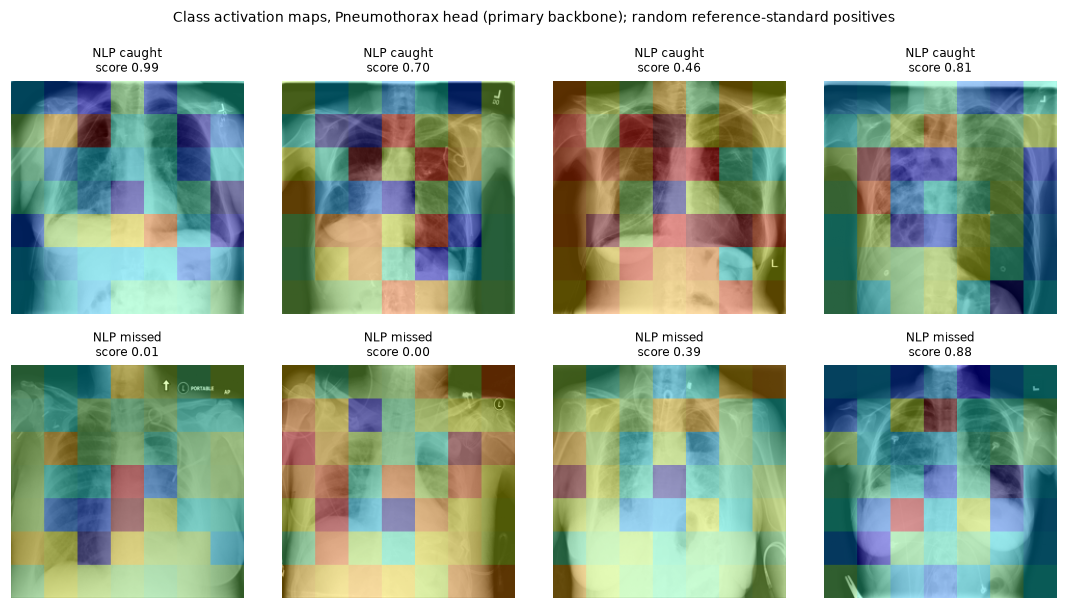

In [18]:
def cam_figure(finding="Pneumothorax", n_each=4):
    try:
        import torch as T
        from PIL import Image
    except Exception:
        print("torch or PIL unavailable; CAM figure skipped."); return None
    if "image_path" not in EVAL.columns or not Path(str(EVAL["image_path"].iloc[0])).exists():
        print("Image files not found; CAM figure skipped."); return None
    bb = pc.build_backbone(P)
    if bb is None: return None
    head, scaler = MODELS[P]["heads"][finding], MODELS[P]["scaler"]
    w_eff = head.coef_[0] / scaler.scale_
    d = EVAL[EVAL["adj_" + finding] == 1]; r = np.random.default_rng(CFG.random_seed)
    picks = [("NLP caught", d[d["nlp_" + finding] == 1]), ("NLP missed", d[d["nlp_" + finding] == 0])]
    fig, axs = plt.subplots(2, n_each, figsize=(2.6 * n_each, 5.6)); used = []
    for row, (lab, dd) in enumerate(picks):
        sel = dd.iloc[r.choice(len(dd), min(n_each, len(dd)), replace=False)]
        for j, (_, rr) in enumerate(sel.iterrows()):
            img = Image.open(rr["image_path"]).convert("L"); x = bb.preprocess(img)[None]
            with T.no_grad():
                A = T.relu(bb.model.features(x))[0].numpy()
            cam = np.tensordot(w_eff, A, axes=(0, 0)); cam = np.kron(cam, np.ones((32, 32)))
            ax = axs[row, j]; ax.imshow(np.asarray(img.resize((224, 224))), cmap="gray")
            ax.imshow(cam, cmap="jet", alpha=0.35); ax.axis("off")
            ax.set_title(f"{lab}\nscore {rr['score_' + finding]:.2f}", fontsize=8)
            used.append({"group": lab, "image": rr["Image Index"], "score": rr["score_" + finding]})
    plt.suptitle(f"Class activation maps, {finding} head (primary backbone); random reference-standard positives", fontsize=9)
    plt.savefig(CFG.fig_dir / "fig11_cam_examples.png", bbox_inches="tight"); plt.show()
    pd.DataFrame(used).to_csv(CFG.tab_dir / "table_cam_images.csv", index=False)
cam_figure()

---
## H. Computational cost (R1.4)

Embedding extraction times come from the manifests written when each embedding was computed; head training and inference were timed in this notebook; analysis run times were collected by Parts 2 to 4 in `provenance/timings.json`.

In [19]:
rows = []
for man in sorted(CFG.emb_dir.glob("*__manifest.json")):
    m_ = json.loads(man.read_text()); tag, bb = m_.get("tag", m_.get("dataset")), m_.get("backbone")
    if tag not in ("train", "val", "evalclean"): continue
    rows.append({"backbone": bb, "split": tag, "images": m_["n"], "extraction_seconds": m_.get("seconds"),
                 "extraction_ms_per_image": 1000 * m_.get("seconds", np.nan) / max(1, m_["n"])})
EXTRACT = pd.DataFrame(rows)
rows = []
for bb, ht in HEAD_TIMES.items():
    for f in ht.get("fit_s", {}):
        ex = EXTRACT[(EXTRACT["backbone"] == bb) & (EXTRACT["split"] == "evalclean")]
        ms_ex = float(ex["extraction_ms_per_image"].iloc[0]) if len(ex) else np.nan
        ms_head = 1000 * ht["eval_inference_s"][f] / ht["n_eval"]
        rows.append({"backbone": bb, "finding": f, "head_training_seconds": ht["fit_s"][f], "head_inference_ms_per_image": ms_head,
                     "embedding_ms_per_image": ms_ex, "end_to_end_inference_ms_per_image": ms_ex + ms_head})
COST = pd.DataFrame(rows)
EXTRACT.to_csv(CFG.tab_dir / "table20a_extraction_cost.csv", index=False); COST.to_csv(CFG.tab_dir / "table20b_training_inference_cost.csv", index=False)
display(EXTRACT.round(2)); display(COST.round(3))
TIMES.save()
tj = json.loads((CFG.prov_dir / "timings.json").read_text())
RUNT = pd.DataFrame([{"part": p_, "step": k, "seconds": v} for p_, d in tj.items() for k, v in d.items()])
RUNT.to_csv(CFG.tab_dir / "table20c_analysis_runtimes.csv", index=False); display(RUNT)
HW = pc.hardware_info(); pc.write_json(CFG.prov_dir / "hardware.json", HW); print(HW)

,backbone,split,images,extraction_seconds,extraction_ms_per_image
0,clip_vitb32,evalclean,4376,237.86,54.36
1,resnet50_imagenet,evalclean,4376,288.31,65.88
2,xrv_densenet121,evalclean,4376,1528.08,349.20
3,clip_vitb32,train,20000,1144.61,57.23
4,resnet50_imagenet,train,20000,1917.00,95.85
5,xrv_densenet121,train,20000,6839.21,341.96
6,clip_vitb32,val,12930,739.13,57.16
7,resnet50_imagenet,val,12930,1456.27,112.63
8,xrv_densenet121,val,12930,4494.60,347.61


,backbone,finding,head_training_seconds,head_inference_ms_per_image,embedding_ms_per_image,end_to_end_inference_ms_per_image
0,xrv_densenet121,Airspace opacity,8.321,0.003,349.196,349.198
1,xrv_densenet121,Pneumothorax,11.064,0.002,349.196,349.198
2,xrv_densenet121,Nodule or mass,12.487,0.002,349.196,349.198
3,resnet50_imagenet,Airspace opacity,2.363,0.004,65.884,65.888
4,resnet50_imagenet,Pneumothorax,6.669,0.004,65.884,65.889
5,resnet50_imagenet,Nodule or mass,3.324,0.004,65.884,65.889
6,clip_vitb32,Airspace opacity,2.551,0.002,54.356,54.357
7,clip_vitb32,Pneumothorax,5.166,0.001,54.356,54.357
8,clip_vitb32,Nodule or mass,3.031,0.002,54.356,54.357


,part,step,seconds
0,part2,load_masters_and_cohort,0.2110
1,part2,embeddings_xrv_densenet121,0.1000
2,part2,regime_difference_table_primary,78.9080
3,part2,noise_table,7.2420
4,part2,subgroup_auroc_table,8.9980
5,part2,regime_table_xrv_densenet121,35.0190
6,part2,embeddings_resnet50_imagenet,0.1810
7,part2,regime_table_resnet50_imagenet,34.2500
8,part2,embeddings_clip_vitb32,0.0730
9,part2,regime_table_clip_vitb32,33.7930


{'platform': 'Windows-10-10.0.26300-SP0', 'processor': 'Intel64 Family 6 Model 181 Stepping 0, GenuineIntel', 'logical_cpus': 14, 'python': '3.11.15', 'ram_gb': 33.8}


---
## I. Key numbers for the response letter and the revised manuscript (R1.3)

Every number below is read from the tables written by Parts 2 to 4.

In [22]:
import shutil
from pathlib import Path
SRC = Path(r"C:\Users\kruta\Downloads\phantom-fairness-revision2\phantom-fairness-main\notebooks\phantom_fairness\tables")
DST = CFG.tab_dir   # Downloads\phantom_fairness\tables

# keep the June originals before overwriting
bak = DST / "v1_original"; bak.mkdir(exist_ok=True)
for f in SRC.glob("table10*.csv"):
    old = DST / f.name
    if old.exists() and not (bak / f.name).exists():
        shutil.copy2(old, bak / f.name)
    shutil.copy2(f, old)
    print("copied", f.name)

copied table10a_instance_dependence.csv
copied table10b_instance_dependence_backbones.csv
copied table10c_injection_bootstrap_replicates.csv
copied table10c_injection_bootstrap_summary.csv
copied table10d_injection_crossfit_replicates.csv
copied table10d_injection_crossfit_summary.csv
copied table10e_evidence_summary.csv
copied table10_phantom_decomposition.csv


In [23]:
def _r(name):
    p = CFG.tab_dir / name
    return pd.read_csv(p) if p.exists() else None
K = {}
t2 = _r("table2_headline_phantom_fairness.csv")
if t2 is not None:
    K["regime_difference"] = {"positive_of_24": int((t2["regime_diff"] > 0).sum()), "median": round(float(t2["regime_diff"].median()), 3),
                              "patient_intervals_excluding_zero": int(((t2["diff_lo_patient"] > 0) | (t2["diff_hi_patient"] < 0)).sum()),
                              "min_bh_p_patient": round(float(t2["p_bh_patient"].min()), 3),
                              "median_ci_width_ratio_patient_vs_image": round(float(t2["ci_width_ratio_patient_vs_image"].median()), 2)}
    pw = t2[(t2["finding"] == "Pneumothorax") & (t2["axis"] == "elderly_women") & (t2["metric"] == "tpr")]
    if len(pw): K["pneumothorax_older_women_tpr"] = {k: round(float(pw[k].iloc[0]), 3) for k in ("gap_nlp", "gap_ref", "regime_diff", "diff_lo_patient", "diff_hi_patient", "p_two_patient")}
t10 = _r("table10b_instance_dependence_backbones.csv")
if t10 is not None:
    K["instance_dependence_nlp_trained"] = {"tests": len(t10), "positive_r": int((t10["rank_biserial"] > 0).sum()),
                                            "sig_patient_boot_bh": int((t10["p_patient_boot_bh"] < 0.05).sum()),
                                            "sig_wcr_bh": int((t10["p_wcr_bh"] < 0.05).sum()), "sig_gee_adj_bh": int((t10["p_gee_adj_bh"] < 0.05).sum()),
                                            "median_r_by_backbone": t10.groupby("score_source")["rank_biserial"].median().round(3).to_dict()}
t13 = _r("table13_instance_dependence_nlp_independent.csv")
if t13 is not None:
    K["instance_dependence_nlp_independent"] = {"tests": len(t13), "positive_r": int((t13["rank_biserial"] > 0).sum()),
                                                "sig_patient_boot_bh": int((t13["p_patient_boot_bh"] < 0.05).sum()),
                                                "sig_gee_adj_bh": int((t13["p_gee_adj_bh"] < 0.05).sum()),
                                                "median_r_by_type": t13.groupby("score_type")["rank_biserial"].median().round(3).to_dict()}
tb = _r("table10c_injection_bootstrap_summary.csv"); tx = _r("table10d_injection_crossfit_summary.csv")
if tb is not None:
    K["injection_bootstrap"] = tb[["finding", "axis", "phantom_observed", "observed_lo", "observed_hi", "phantom_classcond", "phantom_calibrated",
                                   "phantom_instancedep"]].round(3).to_dict(orient="records")
if tx is not None:
    K["injection_crossfit_pooled"] = tx[tx["axis"] == "pooled"][["random_MAE", "calibrated_MAE", "hardest_MAE"]].round(3).to_dict(orient="records")
if "SIZE" in globals():
    K["reference_set_size_median_patients_80pct_power"] = {f"delta_{d:.2f}": int(SIZE[f"patients_needed_delta_{d:.2f}"].median()) for d in (0.05, 0.10, 0.15)}
    K["reference_set_size_current_patients"] = int(SIZE["patients_now"].iloc[0])
if "GRID" in globals():
    K["hyperparameter_selected_C"] = {f"{r.backbone}|{r.finding}": r.C for r in SEL.itertuples()}
if "CVS" in globals():
    K["grouped_cv_rank_biserial_range"] = {f: [round(float(CVS.loc[f, ("rank_biserial", "min")]), 3), round(float(CVS.loc[f, ("rank_biserial", "max")]), 3)] for f in CVS.index}
t20 = _r("table20b_training_inference_cost.csv")
if t20 is not None and len(t20):
    K["compute"] = {"head_training_seconds_range": [round(float(t20["head_training_seconds"].min()), 2), round(float(t20["head_training_seconds"].max()), 2)],
                    "end_to_end_ms_per_image_by_backbone": t20.groupby("backbone")["end_to_end_inference_ms_per_image"].mean().round(1).to_dict()}
K["hardware"] = pc.hardware_info()
pc.write_json(CFG.tab_dir / "REVISION_KEY_NUMBERS.json", K)
print(json.dumps(K, indent=2, default=str))

{
  "regime_difference": {
    "positive_of_24": 16,
    "median": 0.021,
    "patient_intervals_excluding_zero": 1,
    "min_bh_p_patient": 0.778,
    "median_ci_width_ratio_patient_vs_image": 1.05
  },
  "pneumothorax_older_women_tpr": {
    "gap_nlp": 0.064,
    "gap_ref": 0.184,
    "regime_diff": 0.12,
    "diff_lo_patient": -0.074,
    "diff_hi_patient": 0.235,
    "p_two_patient": 0.265
  },
  "instance_dependence_nlp_trained": {
    "tests": 12,
    "positive_r": 12,
    "sig_patient_boot_bh": 12,
    "sig_wcr_bh": 8,
    "sig_gee_adj_bh": 8,
    "median_r_by_backbone": {
      "clip_vitb32": 0.152,
      "resnet50_imagenet": 0.16,
      "xrv_densenet121": 0.202,
      "xrv_densenet121_chex": 0.134
    }
  },
  "instance_dependence_nlp_independent": {
    "tests": 12,
    "positive_r": 11,
    "sig_patient_boot_bh": 10,
    "sig_gee_adj_bh": 8,
    "median_r_by_type": {
      "reference-trained head (cross-fitted)": 0.153,
      "zero-shot CheXpert model": 0.108
    }
  },
  "i

---
## J. Provenance and combined manifest

In [24]:
prov = {"part": "4 (revision 2)", "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "seed": CFG.random_seed,
        "backbones": list(EVALS), "n_bootstrap": CFG.n_bootstrap, "versions": VERSIONS,
        "tables": {p.name: pc.sha256_file(p) for p in sorted(CFG.tab_dir.glob("table1[3-9]*.csv")) + sorted(CFG.tab_dir.glob("table2[0-9]*.csv"))
                   + sorted(CFG.tab_dir.glob("table_backbone*.csv"))},
        "figures": {p.name: pc.sha256_file(p) for p in sorted(CFG.fig_dir.glob("fig1[1-3]*.png"))}}
pc.write_json(CFG.prov_dir / "provenance_part4.json", prov)
combined = {"project": "phantom_fairness", "revision": 2, "parts": {}}
for pj in sorted(CFG.prov_dir.glob("provenance_part*.json")):
    try: combined["parts"][pj.stem] = json.loads(pj.read_text())
    except Exception: pass
combined["all_tables"] = {p.name: pc.sha256_file(p) for p in sorted(CFG.tab_dir.glob("*.csv"))}
combined["all_figures"] = {p.name: pc.sha256_file(p) for p in sorted(CFG.fig_dir.glob("*.png"))}
combined["phantom_core_sha256"] = pc.sha256_file(Path(pc.__file__))
pc.write_json(CFG.prov_dir / "MANIFEST_phantom_fairness.json", combined)
print("Manifest:", len(combined["all_tables"]), "tables,", len(combined["all_figures"]), "figures")

Manifest: 58 tables, 15 figures
